Setup and reproducibility

In [1]:
# If needed in Colab, uncomment:
# %pip -q install pandas numpy matplotlib seaborn scikit-learn statsmodels reportlab

import os, io, math, random, warnings, textwrap
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score,
                             classification_report)
import statsmodels.api as sm
from scipy.stats import norm

SEED = 179
np.random.seed(SEED)
random.seed(SEED)
OUT = Path("assignment_2179_outputs")
OUT.mkdir(exist_ok=True)
print("Roll number: 2179 | random_state:", SEED)
print("Output folder:", OUT.resolve())

Roll number: 2179 | random_state: 179
Output folder: /content/assignment_2179_outputs


Load Adult Census Income data

In [2]:
import urllib.request

URLS = {
    "train": "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data",
    "test":  "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.test",
}
COLUMNS = ["age","workclass","fnlwgt","education","education-num","marital-status",
           "occupation","relationship","race","sex","capital-gain","capital-loss",
           "hours-per-week","native-country","income"]

def read_adult_url(url, is_test=False):
    # pandas can read URLs directly in Colab; local fallback also supported.
    df = pd.read_csv(url, header=None, names=COLUMNS, skipinitialspace=True,
                     comment="|" if is_test else None, skiprows=1 if is_test else 0)
    df["income"] = df["income"].astype(str).str.strip().str.rstrip(".")
    return df

try:
    adult_train = read_adult_url(URLS["train"], False)
    adult_test = read_adult_url(URLS["test"], True)
    df = pd.concat([adult_train, adult_test], ignore_index=True)
except Exception as e:
    raise RuntimeError("Dataset download failed. Run this notebook in Colab with internet access, or place adult.data and adult.test in the working directory and load them manually. Original error: " + str(e))

df = df.replace("?", np.nan)
df = df.dropna(subset=["income"]).copy()
df["income_binary"] = (df["income"].str.strip() == ">50K").astype(int)
print("Combined shape:", df.shape)
display(df.head())
display(df["income"].value_counts(dropna=False).rename("count").to_frame())
print("Missing values by column:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

Combined shape: (48842, 16)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income,income_binary
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K,0
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K,0
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K,0
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K,0
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K,0


,count
income,
<=50K,37155
>50K,11687


Missing values by column:


,missing_count
occupation,2809
workclass,2799
native-country,857
fnlwgt,0
education,0
education-num,0
marital-status,0
age,0
relationship,0
race,0


Preprocessing decisions

In [3]:
target = "income_binary"
sensitive = "sex"
drop_cols = ["income", target]
X = df.drop(columns=drop_cols).copy()
y = df[target].astype(int).copy()

# Explicitly hold sensitive attribute for fairness auditing; exclude it from model predictors.
audit_sex = X[sensitive].fillna("Unknown").astype(str)
X_model = X.drop(columns=[sensitive])

numeric_features = X_model.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_model.select_dtypes(exclude=["number"]).columns.tolist()

X_train, X_test, y_train, y_test, sex_train, sex_test = train_test_split(
    X_model, y, audit_sex, test_size=0.30, random_state=SEED, stratify=y
)

numeric_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                         ("scaler", StandardScaler())])
categorical_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                             ("onehot", OneHotEncoder(handle_unknown="ignore"))])
preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("cat", categorical_pipe, categorical_features)
])

linear_model = Pipeline([("prep", preprocessor), ("model", LinearRegression())])
logit_model = Pipeline([("prep", preprocessor),
                        ("model", LogisticRegression(max_iter=2000, random_state=SEED))])
linear_model.fit(X_train, y_train)
logit_model.fit(X_train, y_train)

lin_pred = linear_model.predict(X_test)
logit_prob = logit_model.predict_proba(X_test)[:, 1]
logit_pred = (logit_prob >= 0.5).astype(int)

# Numeric outlier summary using training data only
outlier_rows = []
for col in numeric_features:
    s = X_train[col].dropna()
    q1, q3 = s.quantile([.25, .75])
    iqr = q3-q1
    lo, hi = q1-1.5*iqr, q3+1.5*iqr
    outlier_rows.append({"feature": col, "Q1": q1, "Q3": q3, "IQR": iqr,
                         "lower_fence": lo, "upper_fence": hi,
                         "training_outlier_count": int(((s<lo)|(s>hi)).sum())})
outlier_table = pd.DataFrame(outlier_rows)
display(outlier_table)
print(f"Train rows: {len(X_train):,}; test rows: {len(X_test):,}; train fraction: {len(X_train)/(len(X_train)+len(X_test)):.3f}")
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

,feature,Q1,Q3,IQR,lower_fence,upper_fence,training_outlier_count
0,age,28.0,48.0,20.0,-2.0,78.0,139
1,fnlwgt,117503.0,237943.0,120440.0,-63157.0,418603.0,1017
2,education-num,9.0,12.0,3.0,4.5,16.5,1242
3,capital-gain,0.0,0.0,0.0,0.0,0.0,2845
4,capital-loss,0.0,0.0,0.0,0.0,0.0,1593
5,hours-per-week,40.0,45.0,5.0,32.5,52.5,9401


Train rows: 34,189; test rows: 14,653; train fraction: 0.700
Numeric features: ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Categorical features: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'native-country']


Part 1 Build

In [4]:
median_linear = float(np.median(lin_pred))
lin_flag = (lin_pred >= median_linear).astype(int)
agreement_cm = confusion_matrix(lin_flag, logit_pred, labels=[0,1])
mismatch = (lin_flag != logit_pred)
part1 = {
    "test_rows": int(len(y_test)),
    "linear_prediction_median": median_linear,
    "logistic_threshold": 0.5,
    "mismatch_count": int(mismatch.sum()),
    "mismatch_percent": float(100*mismatch.mean()),
    "agreement_percent": float(100*(~mismatch).mean()),
    "linear_median_flag_positive_rate": float(lin_flag.mean()),
    "logistic_flag_positive_rate": float(logit_pred.mean()),
    "logistic_accuracy": float(accuracy_score(y_test, logit_pred)),
    "logistic_precision": float(precision_score(y_test, logit_pred, zero_division=0)),
    "logistic_recall": float(recall_score(y_test, logit_pred, zero_division=0)),
    "logistic_f1": float(f1_score(y_test, logit_pred, zero_division=0)),
    "logistic_auc": float(roc_auc_score(y_test, logit_prob)),
}
print(pd.Series(part1).to_string())
print("\nConfusion matrix (rows=Linear threshold flag, columns=Logistic flag), labels [0,1]:")
display(pd.DataFrame(agreement_cm, index=["Linear low","Linear high"], columns=["Logistic low","Logistic high"]))
print("\nLogistic regression classification report against actual income:")
print(classification_report(y_test, logit_pred, target_names=["<=50K"," >50K"], zero_division=0))
pd.DataFrame(agreement_cm, index=["Linear low","Linear high"], columns=["Logistic low","Logistic high"]).to_csv(OUT/"part1_agreement_confusion_matrix.csv")
pd.Series(part1).to_csv(OUT/"part1_metrics.csv")

test_rows                           14653.000000
linear_prediction_median                0.233386
logistic_threshold                      0.500000
mismatch_count                       4463.000000
mismatch_percent                       30.457927
agreement_percent                      69.542073
linear_median_flag_positive_rate        0.500034
logistic_flag_positive_rate             0.198048
logistic_accuracy                       0.851361
logistic_precision                      0.728808
logistic_recall                         0.603252
logistic_f1                             0.660112
logistic_auc                            0.902733

Confusion matrix (rows=Linear threshold flag, columns=Logistic flag), labels [0,1]:


,Logistic low,Logistic high
Linear low,7307,19
Linear high,4444,2883



Logistic regression classification report against actual income:
              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.90     11147
        >50K       0.73      0.60      0.66      3506

    accuracy                           0.85     14653
   macro avg       0.81      0.77      0.78     14653
weighted avg       0.85      0.85      0.85     14653



Part 2.1 Simpson's paradox hunt

In [5]:
def make_statsmodels_design(frame, y_series, include=None, exclude_sensitive=True):
    # Statsmodels logit with dummy encoding; standardize numeric columns to aid convergence.
    xx = frame.copy()
    if exclude_sensitive and sensitive in xx.columns:
        xx = xx.drop(columns=[sensitive])
    if include is not None:
        xx = xx[include]
    for c in xx.select_dtypes(include=["object"]).columns:
        xx[c] = xx[c].fillna("Unknown")
    for c in xx.select_dtypes(include=["number"]).columns:
        xx[c] = xx[c].fillna(xx[c].median())
        sd = xx[c].std()
        if sd and np.isfinite(sd):
            xx[c] = (xx[c]-xx[c].mean())/sd
    xx = pd.get_dummies(xx, drop_first=True, dtype=float)
    xx = sm.add_constant(xx, has_constant="add")
    yy = pd.Series(y_series, index=frame.index).astype(int)
    return xx.astype(float), yy

def fit_sm_logit(frame, yy):
    xx, yy = make_statsmodels_design(frame, yy)
    model = sm.Logit(yy, xx).fit(disp=False, maxiter=200)
    return model, xx.columns

# Fit using training data only for inferential coefficient comparisons
full_sm, full_cols = fit_sm_logit(X_train, y_train)
subgroup_results = []
for label in ["Female", "Male"]:
    mask = sex_train.astype(str).values == label
    # use the same feature list/encoding procedure within each subgroup
    sm_model, sm_cols = fit_sm_logit(X_train.loc[mask], y_train.loc[mask])
    for group, model in [("Full training set", full_sm), (label, sm_model)]:
        if "age" in model.params.index:
            subgroup_results.append({"group": group, "predictor": "age",
                                     "coefficient": model.params["age"],
                                     "ci_lower": model.conf_int().loc["age",0],
                                     "ci_upper": model.conf_int().loc["age",1],
                                     "p_value": model.pvalues["age"]})
subgroup_table = pd.DataFrame(subgroup_results).drop_duplicates("group")
display(subgroup_table)
subgroup_table.to_csv(OUT/"subgroup_age_coefficients.csv", index=False)

# Compare effect sizes in group-specific fitted models even if signs do not reverse.
print("Interpretation: coefficients are log-odds changes per standardized age unit. Compare sign, magnitude, and CI overlap; this is a subgroup-effect comparison, not proof of causality.")

/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,group,predictor,coefficient,ci_lower,ci_upper,p_value
0,Full training set,age,0.342695,0.299386,0.386004,3.026904e-54
1,Female,age,0.437749,0.326336,0.549161,1.351589e-14
3,Male,age,0.321730,0.275009,0.368450,1.631031e-41


Interpretation: coefficients are log-odds changes per standardized age unit. Compare sign, magnitude, and CI overlap; this is a subgroup-effect comparison, not proof of causality.


Part 2.2 Omitted-variable bias

In [6]:
# Use statsmodels models with a consistent design; selected interpretable variables include age,
# hours-per-week, capital-gain, capital-loss, and education-num.
def build_sm_matrix(frame, yseries, drop_feature=None):
    xx = frame.drop(columns=[sensitive], errors="ignore").copy()
    if drop_feature and drop_feature in xx.columns:
        xx = xx.drop(columns=[drop_feature])
    for c in xx.select_dtypes(include=["object"]).columns:
        xx[c] = xx[c].fillna("Unknown")
    for c in xx.select_dtypes(include=["number"]).columns:
        xx[c] = xx[c].fillna(xx[c].median())
        sd = xx[c].std()
        if sd and np.isfinite(sd):
            xx[c] = (xx[c]-xx[c].mean())/sd
    xx = pd.get_dummies(xx, drop_first=True, dtype=float)
    xx = sm.add_constant(xx, has_constant="add")
    return xx.astype(float), pd.Series(yseries, index=frame.index).astype(int)

Xfull_sm, yfull_sm = build_sm_matrix(X_train, y_train)
Xred_sm, yred_sm = build_sm_matrix(X_train, y_train, drop_feature="education-num")
# Align model comparison to predictors that exist in both matrices.
common_cols = Xfull_sm.columns.intersection(Xred_sm.columns)
full_omit = sm.Logit(yfull_sm, Xfull_sm).fit(disp=False, maxiter=200)
reduced_omit = sm.Logit(yred_sm, Xred_sm).fit(disp=False, maxiter=200)
candidate_terms = ["age", "hours-per-week", "capital-gain", "capital-loss"]
omit_rows = []
for term in candidate_terms:
    if term in full_omit.params.index and term in reduced_omit.params.index:
        b1, b2 = float(full_omit.params[term]), float(reduced_omit.params[term])
        pct = 100*(b2-b1)/abs(b1) if abs(b1)>1e-8 else np.nan
        omit_rows.append({"predictor": term, "full_coefficient": b1,
                          "reduced_coefficient": b2, "absolute_change": abs(b2-b1),
                          "percent_change": pct})
omit_table = pd.DataFrame(omit_rows)
display(omit_table)
if not omit_table.empty:
    print("Largest absolute coefficient shift:", omit_table.loc[omit_table["absolute_change"].idxmax(),"predictor"])
omit_table.to_csv(OUT/"omitted_variable_coefficients.csv", index=False)

/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,predictor,full_coefficient,reduced_coefficient,absolute_change,percent_change
0,age,0.342695,0.342695,1.757594e-12,-5.128746e-10
1,hours-per-week,0.357073,0.357073,3.911316e-13,1.095382e-10
2,capital-gain,2.393111,2.393111,3.122524e-11,-1.304797e-09
3,capital-loss,0.272195,0.272195,3.759215e-13,-1.381072e-10


Largest absolute coefficient shift: capital-gain


Part 2.3 Adversarial subset construction

In [7]:
test_results = X_test.copy()
test_results["actual"] = np.asarray(y_test)
test_results["probability"] = logit_prob
test_results["predicted"] = logit_pred
test_results["sex_audit"] = np.asarray(sex_test)
test_results["error_type"] = np.where(
    (test_results["probability"] >= .75) & (test_results["actual"] == 0), "False positive",
    np.where((test_results["probability"] <= .25) & (test_results["actual"] == 1), "False negative", ""))
adversarial_all = test_results[test_results["error_type"] != ""].copy()
n_confident_wrong = len(adversarial_all)
if n_confident_wrong > 50:
    adversarial = adversarial_all.sample(50, random_state=SEED)
else:
    adversarial = adversarial_all.copy()
print(f"High-confidence wrong predictions: {n_confident_wrong:,} / {len(test_results):,} test rows = {100*n_confident_wrong/len(test_results):.3f}%")
print("Rows selected for subset:", len(adversarial))
if len(adversarial):
    print("\nAdversarial subset error types:")
    display(adversarial["error_type"].value_counts().to_frame("count"))
    print("\nAge summary: adversarial subset vs full test:")
    display(pd.DataFrame({"adversarial": adversarial["age"].describe(),
                          "full_test": test_results["age"].describe()}))
    print("\nSex composition (%):")
    display(pd.concat([
        adversarial["sex_audit"].value_counts(normalize=True).mul(100).rename("adversarial_percent"),
        test_results["sex_audit"].value_counts(normalize=True).mul(100).rename("test_percent")
    ], axis=1).fillna(0))
    print("\nRace composition (%):")
    display(pd.concat([
        adversarial["race"].value_counts(normalize=True).mul(100).rename("adversarial_percent"),
        test_results["race"].value_counts(normalize=True).mul(100).rename("test_percent")
    ], axis=1).fillna(0))
    # Most frequent category levels across categorical features
    trait_rows = []
    for col in categorical_features:
        subset_share = adversarial[col].value_counts(normalize=True, dropna=False).head(1)
        overall_share = test_results[col].value_counts(normalize=True, dropna=False)
        if len(subset_share):
            value = subset_share.index[0]
            trait_rows.append({"feature": col, "most_common_value_in_subset": value,
                               "subset_percent": 100*subset_share.iloc[0],
                               "full_test_percent_same_value": 100*overall_share.get(value, 0)})
    trait_table = pd.DataFrame(trait_rows).sort_values("subset_percent", ascending=False)
    display(trait_table)
    trait_table.to_csv(OUT/"adversarial_common_traits.csv", index=False)
else:
    print("No confident wrong predictions under the assignment's probability cutoffs.")
adversarial.to_csv(OUT/"adversarial_subset.csv", index=False)

High-confidence wrong predictions: 778 / 14,653 test rows = 5.309%
Rows selected for subset: 50

Adversarial subset error types:


,count
error_type,
False negative,38
False positive,12



Age summary: adversarial subset vs full test:


,adversarial,full_test
count,50.00000,14653.000000
mean,43.70000,38.786665
std,12.40844,13.855508
min,21.00000,17.000000
25%,34.25000,28.000000
50%,41.50000,37.000000
75%,54.75000,48.000000
max,67.00000,90.000000



Sex composition (%):


,adversarial_percent,test_percent
sex_audit,,
Male,82.0,66.77131
Female,18.0,33.22869



Race composition (%):


,adversarial_percent,test_percent
race,,
White,90.0,85.804955
Asian-Pac-Islander,6.0,3.030096
Black,4.0,9.451989
Other,0.0,0.873541
Amer-Indian-Eskimo,0.0,0.839419


,feature,most_common_value_in_subset,subset_percent,full_test_percent_same_value
6,native-country,United-States,94.0,89.851907
5,race,White,90.0,85.804955
0,workclass,Private,70.0,69.507951
2,marital-status,Married-civ-spouse,60.0,46.004231
4,relationship,Husband,50.0,40.305739
1,education,HS-grad,26.0,32.082167
3,occupation,Exec-managerial,22.0,12.447963


Part 2.4 — Fairness trade-off analysis

,threshold,DP_ratio,EO_ratio,PP_ratio,Female_positive_rate,Male_positive_rate,Female_TPR,Male_TPR,Female_FPR,Male_FPR,Female_precision,Male_precision,accuracy
0,0.05,0.5976,0.6071,0.6011,0.4173,0.6984,0.9612,0.9811,0.3494,0.5755,0.2559,0.4257,0.6238
1,0.15,0.4013,0.3672,0.8382,0.2224,0.5543,0.8521,0.9288,0.1437,0.3914,0.4257,0.5078,0.7555
2,0.25,0.3536,0.3009,0.9379,0.1557,0.4402,0.7597,0.8398,0.0802,0.2665,0.5422,0.5781,0.8110
3,0.35,0.3379,0.2846,0.9590,0.1181,0.3494,0.6562,0.7423,0.0508,0.1786,0.6174,0.6438,0.8370
4,0.45,0.3257,0.2588,0.9942,0.0930,0.2857,0.5841,0.6614,0.0317,0.1223,0.6976,0.7016,0.8499
5,0.55,0.3021,0.2239,1.0183,0.0686,0.2271,0.4713,0.5619,0.0183,0.0815,0.7635,0.7498,0.8485
6,0.65,0.2925,0.2343,0.9950,0.0505,0.1727,0.3678,0.4634,0.0109,0.0463,0.8089,0.8130,0.8433
7,0.75,0.2979,0.2538,0.9873,0.0355,0.1193,0.2754,0.3433,0.0055,0.0219,0.8613,0.8723,0.8286
8,0.85,0.3074,0.2780,0.9883,0.0226,0.0735,0.1867,0.2253,0.0021,0.0075,0.9182,0.9291,0.8091
9,0.95,0.2788,0.7480,0.9837,0.0109,0.0390,0.0961,0.1285,0.0002,0.0001,0.9811,0.9974,0.7901


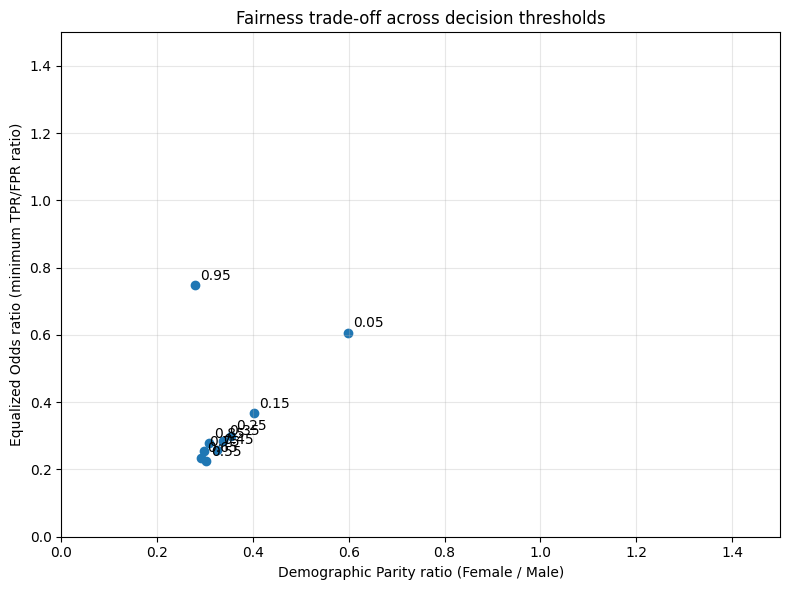

Candidate threshold minimizing combined DP/EO distance from 1.0:


,value
threshold,0.050000
DP_ratio,0.597570
EO_ratio,0.607094
PP_ratio,0.601101
Female_positive_rate,0.417334
Male_positive_rate,0.698385
Female_TPR,0.961183
Male_TPR,0.981113
Female_FPR,0.349353
Male_FPR,0.575451


In [8]:
def safe_ratio(a, b):
    if b == 0 or not np.isfinite(b):
        return np.nan
    return a/b

def group_rates(y_true, y_hat):
    y_true = np.asarray(y_true).astype(int)
    y_hat = np.asarray(y_hat).astype(int)
    tp = np.sum((y_true==1)&(y_hat==1)); fn = np.sum((y_true==1)&(y_hat==0))
    fp = np.sum((y_true==0)&(y_hat==1)); tn = np.sum((y_true==0)&(y_hat==0))
    tpr = tp/(tp+fn) if tp+fn else np.nan
    fpr = fp/(fp+tn) if fp+tn else np.nan
    ppr = np.mean(y_hat==1) if len(y_hat) else np.nan
    precision = tp/(tp+fp) if tp+fp else np.nan
    return {"TPR":tpr, "FPR":fpr, "positive_rate":ppr, "precision":precision}

threshold_rows = []
sex_test_arr = np.asarray(sex_test).astype(str)
y_test_arr = np.asarray(y_test).astype(int)
for t in np.round(np.arange(.05, .951, .10), 2):
    pred_t = (logit_prob >= t).astype(int)
    female = sex_test_arr == "Female"
    male = sex_test_arr == "Male"
    rf = group_rates(y_test_arr[female], pred_t[female])
    rm = group_rates(y_test_arr[male], pred_t[male])
    dp = safe_ratio(rf["positive_rate"], rm["positive_rate"])
    tpr_ratio = safe_ratio(rf["TPR"], rm["TPR"])
    fpr_ratio = safe_ratio(rf["FPR"], rm["FPR"])
    eo = np.nanmin([tpr_ratio, fpr_ratio]) if np.isfinite(tpr_ratio) or np.isfinite(fpr_ratio) else np.nan
    pp = safe_ratio(rf["precision"], rm["precision"])
    threshold_rows.append({"threshold":t, "DP_ratio":dp, "EO_ratio":eo, "PP_ratio":pp,
                           "Female_positive_rate":rf["positive_rate"], "Male_positive_rate":rm["positive_rate"],
                           "Female_TPR":rf["TPR"], "Male_TPR":rm["TPR"],
                           "Female_FPR":rf["FPR"], "Male_FPR":rm["FPR"],
                           "Female_precision":rf["precision"], "Male_precision":rm["precision"],
                           "accuracy":accuracy_score(y_test_arr,pred_t)})
fairness_table = pd.DataFrame(threshold_rows)
display(fairness_table.round(4))
fairness_table.to_csv(OUT/"fairness_threshold_sweep.csv", index=False)

plt.figure(figsize=(8,6))
valid = fairness_table.dropna(subset=["DP_ratio","EO_ratio"])
plt.scatter(valid["DP_ratio"], valid["EO_ratio"])
for _, r in valid.iterrows():
    plt.annotate(f'{r["threshold"]:.2f}', (r["DP_ratio"], r["EO_ratio"]), xytext=(4,4), textcoords="offset points")
plt.xlim(0,1.5); plt.ylim(0,1.5)
plt.xlabel("Demographic Parity ratio (Female / Male)")
plt.ylabel("Equalized Odds ratio (minimum TPR/FPR ratio)")
plt.title("Fairness trade-off across decision thresholds")
plt.grid(True, alpha=.3)
plt.tight_layout()
plt.savefig(OUT/"fairness_tradeoff.png", dpi=180)
plt.show()

# Pick a defensible threshold as the valid point minimizing distance from parity on DP and EO,
# while reporting accuracy and predictive parity as explicit counterweights.
fairness_table["parity_distance"] = np.sqrt((fairness_table["DP_ratio"]-1)**2 + (fairness_table["EO_ratio"]-1)**2)
eligible = fairness_table.dropna(subset=["DP_ratio","EO_ratio"])
recommended_row = eligible.loc[eligible["parity_distance"].idxmin()] if len(eligible) else None
print("Candidate threshold minimizing combined DP/EO distance from 1.0:")
display(recommended_row.to_frame("value") if recommended_row is not None else pd.DataFrame())